In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import ConnectionPatch
import numpy as np
import pandas as pd
import pyam

<IPython.core.display.Javascript object>

In [2]:
# Load historic data
temp = pd.read_csv("./input/HadCRUT.5.0.2.0.analysis.summary_series.global.annual.csv").rename(
    columns={"Time": "Year", "Anomaly (deg C)": "Temp"})
co2 = pd.read_excel(
    "./input/Global_Carbon_Budget_2025_v0.3.xlsx", 
    sheet_name="Historical Budget", 
    header=15
).fillna(0)
now = 2025

In [3]:
ar6meta = pd.read_excel("./input/AR6_Scenarios_Database_metadata_indicators_v1.1.xlsx", sheet_name="meta_Ch3vetted_withclimate")

In [4]:
# Create a variable for combined CO2 in GtCO2 
co2["CO2"] = (
    co2["fossil emissions excluding carbonation"] + co2["land-use change emissions"] + co2["cement carbonation sink"]
) *3.664

In [5]:
# Merge the datasets on Year, keeping only years where both have data
combined_df = pd.merge(temp, co2, on='Year', how='inner')
combined_df

,Year,Temp,Lower confidence limit (2.5%),Upper confidence limit (97.5%),fossil emissions excluding carbonation,land-use change emissions,atmospheric growth,ocean sink,land sink,cement carbonation sink,budget imbalance,CO2
0,1850,-0.417711,-0.589256,-0.246166,0.053725,0.740727,0.189248,0.164195,0.528177,0.000000,-0.087169,2.910870
1,1851,-0.233350,-0.411868,-0.054832,0.054252,0.769860,0.125528,0.165485,-0.126644,0.000000,0.659742,3.019546
2,1852,-0.229399,-0.409382,-0.049416,0.056658,0.796220,0.069667,0.171645,0.103646,0.000000,0.507920,3.124945
3,1853,-0.270354,-0.430009,-0.110700,0.059290,0.801160,0.009770,0.172905,0.239710,0.000000,0.438064,3.152687
4,1854,-0.291521,-0.432712,-0.150330,0.069607,0.812107,-0.039082,0.174320,0.195157,0.000000,0.551317,3.230597
...,...,...,...,...,...,...,...,...,...,...,...,...
170,2020,0.922921,0.888298,0.957543,9.595587,1.232680,4.948920,3.243302,2.100974,0.213648,0.321422,40.457577
171,2021,0.761906,0.725458,0.798353,10.061917,1.271043,5.033880,3.144615,2.595630,0.224417,0.334419,42.346231
172,2022,0.801305,0.765258,0.837353,10.242296,1.306057,4.863960,3.120451,3.106184,0.220896,0.236861,43.122526
173,2023,1.100313,1.061651,1.138975,10.396846,1.295183,5.734800,3.275431,2.016705,0.227371,0.437723,43.672682


In [6]:
combined_df["Cumulative CO2"] = np.cumsum(combined_df["CO2"])

In [7]:
combined_df["Temp"] = combined_df["Temp"] - combined_df["Temp"][combined_df.Year<1900].mean()

In [8]:
combined_df["meanTemp"] = combined_df["Temp"].rolling(window=10, center=True).mean()
combined_df.tail(15)

,Year,Temp,Lower confidence limit (2.5%),Upper confidence limit (97.5%),fossil emissions excluding carbonation,land-use change emissions,atmospheric growth,ocean sink,land sink,cement carbonation sink,budget imbalance,CO2,Cumulative CO2,meanTemp
160,2010,1.039306,0.649076,0.711667,9.093251,1.778883,5.01264,2.833186,2.676668,0.152220,0.197421,40.393234,2179.943193,0.951502
161,2011,0.896632,0.506001,0.569394,9.410477,1.744693,3.69576,2.867198,3.292777,0.163509,1.135926,41.471645,2221.414837,0.973327
162,2012,0.936542,0.544855,0.610359,9.540048,1.823723,5.11884,2.906325,1.845645,0.171371,1.321591,42.264760,2263.679597,1.009364
163,2013,0.982510,0.588484,0.658667,9.627680,1.724760,5.20380,2.954905,2.715136,0.181213,0.297386,42.259306,2305.938903,1.034712
164,2014,1.031806,0.638905,0.706838,9.679502,1.749430,4.31172,3.082054,3.038601,0.187246,0.809311,42.561674,2348.500577,1.064412
165,2015,1.184049,0.791287,0.858942,9.662535,1.777463,6.26580,3.168268,1.775285,0.189521,0.041124,42.610557,2391.111135,1.093841
166,2016,1.291862,0.901764,0.964091,9.659615,1.467400,6.03216,3.287602,1.983745,0.192174,-0.368665,41.473508,2432.584643,1.118096
167,2017,1.204109,0.814775,0.875574,9.818398,1.448627,4.54536,3.123325,2.849579,0.195180,0.553580,41.997519,2474.582162,1.140517
168,2018,1.121589,0.731052,0.794256,10.025656,1.332430,5.07636,3.214723,2.878236,0.199661,-0.010895,42.347585,2516.929747,1.162887
169,2019,1.250007,0.856787,0.925358,10.121880,1.333837,5.31000,3.242252,2.383930,0.209574,0.309960,42.741623,2559.671370,1.210561


# Approach 1

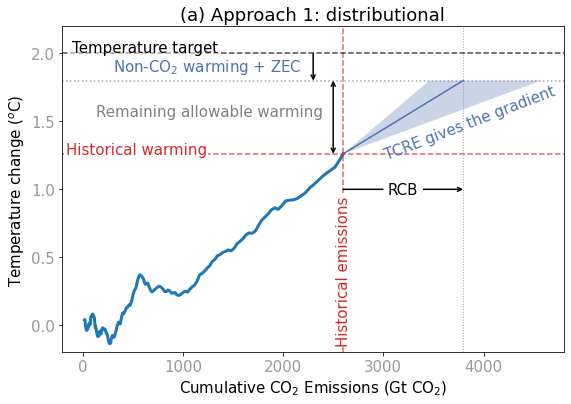

In [9]:
# Define constants
TARGET_Y_1 = 2.0 
TARGET_Y_2 = 1.80 
ARROW_BLUE = '#4C72B0'
BG_COLOR = 'white'
HISTORICAL_COLOR = 'tab:red' # Defined for consistency
fontsize = 15
titlefont = 18

# Get the last data point 
last_co2 = combined_df['Cumulative CO2'].iloc[-5]
last_temp = combined_df['meanTemp'].iloc[-5]

# --- Calculate the Cone Endpoints (RCB Range) ---
m_min = 1/1000/3.664
x_end_max = last_co2 + (TARGET_Y_2 - last_temp) / m_min

m_max = 2.3/1000/3.664
x_end_min = last_co2 + (TARGET_Y_2 - last_temp) / m_max

# And the average
m_av = (1+2.3)/2/1000/3.664
x_end_av = last_co2 + (TARGET_Y_2 - last_temp) / m_av

# Define the vertices for the shaded cone
cone_vertices = np.array([
    (last_co2, last_temp),          
    (x_end_max, TARGET_Y_2),        
    (x_end_min, TARGET_Y_2)         
])

# --- Plotting Code with Annotations ---

fig, ax1 = plt.subplots(figsize=(9, 6))

ax1.set_ylabel('Temperature change ($^o$C)', fontsize=fontsize, color='black') 
ax1.set_xlabel('Cumulative CO$_2$ Emissions (Gt CO$_2$)', fontsize=fontsize, color='black')

# --- A. Plotting Data and Cone ---
color_co2 = 'tab:blue'

ax1.plot(
    combined_df['Cumulative CO2'], 
    combined_df['meanTemp'], 
    color=color_co2, 
    label='Total CO2 Emissions',
    linewidth=3
)

ax1.grid(False)
ax1.set_ylim([-0.2, 2.2])

# Add the cone patch
cone_patch = plt.Polygon(
    cone_vertices, 
    closed=True, 
    facecolor=ARROW_BLUE, 
    alpha=0.3, 
)
ax1.add_patch(cone_patch)

# Cone Label
cone_mid_x = (x_end_min + x_end_max) / 2
cone_center_y = (last_temp + TARGET_Y_2) / 2

ax1.text(
    cone_mid_x-150, 
    cone_center_y - 0.036, 
    "TCRE gives the gradient",
    color=ARROW_BLUE,
    fontsize=fontsize,
    ha='center',
    va='center',
    rotation=21
)

# Plot the best estimate
ax1.plot(
    [last_co2, x_end_av], [last_temp, TARGET_Y_2],
    color=ARROW_BLUE
)

# --- B. Horizontal RCB Arrows ---

# Define Y-positions for the arrows below the plot
ARROW_Y_LEVEL_1 = 1 

# Arrow 1: RCB
ax1.annotate(
    '',
    xy=(x_end_av, ARROW_Y_LEVEL_1),
    xytext=(last_co2, ARROW_Y_LEVEL_1),
    arrowprops=dict(
        arrowstyle="->", 
        color='black', 
        linewidth=1.5,
        shrinkA=0, shrinkB=0, 
        connectionstyle="arc3,rad=0"
    ),
)
ax1.text(
    (last_co2 + x_end_av) / 2, 
    ARROW_Y_LEVEL_1, 
    "RCB",
    fontsize=fontsize,
    ha='center',
    va='center',
    bbox=dict(boxstyle="round,pad=0.3", fc=BG_COLOR, alpha=1.0, ec="none") 
)

# --- C. Vertical Dashed Lines and Text ---

# 1. Vertical line at Historical Emissions
ax1.axvline(
    x=last_co2, 
    color=HISTORICAL_COLOR, 
    linestyle='--', 
    linewidth=1.5, 
    alpha=0.7
)
# Label "Historical emissions"
ax1.text(
    last_co2, 
    -0.15, 
    "Historical emissions", 
    color=HISTORICAL_COLOR, 
    fontsize=fontsize,
    ha='center',
    va='bottom',
    rotation=90,
    bbox=dict(boxstyle="square,pad=0.1", fc=BG_COLOR, ec="none") 
)

# 2. Vertical line at best RCB
ax1.axvline(x=x_end_av, color='grey', linestyle=':', linewidth=1.0, alpha=0.7)


# --- D. Other Lines and Annotations ---

# Historical warming line
ax1.axhline(
    y=last_temp, 
    color=HISTORICAL_COLOR, 
    linestyle='--', 
    linewidth=1.5, 
    alpha=0.7
)
ax1.text(
    ax1.get_xlim()[0] + 40, 
    last_temp + 0.03, 
    "Historical warming", 
    color=HISTORICAL_COLOR, 
    fontsize=fontsize, 
    ha='left',
    va="center",
    bbox=dict(boxstyle="square,pad=0.1", fc=BG_COLOR, ec="none")
)

# Horizontal lines and labels
ax1.axhline(y=TARGET_Y_1, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
ax1.text(
    ax1.get_xlim()[0] + 100, 
    TARGET_Y_1 + 0.04, 
    "Temperature target", 
    color="black", 
    fontsize=fontsize, 
    ha='left',
    va="center",
    bbox=dict(boxstyle="square,pad=0.1", fc=BG_COLOR, ec="none", alpha=0.5) 
)

# Annotation Arrow and Text (Non-CO2 warming + ZEC)
arrow_x_position = last_co2 - 300
ax1.annotate(
    '', 
    xy=(arrow_x_position, TARGET_Y_2),
    xytext=(arrow_x_position, TARGET_Y_1),
    arrowprops=dict(
        arrowstyle="->", 
        color='black', 
        linewidth=1.5,
        shrinkA=0, shrinkB=0,
        connectionstyle="arc3,rad=0"
    )
)

arrow_mid_y = (TARGET_Y_1 + TARGET_Y_2) / 2
ax1.text(
    arrow_x_position - 2000, 
    arrow_mid_y, 
    'Non-CO$_2$ warming + ZEC', 
    color=ARROW_BLUE, 
    fontsize=fontsize,
    ha='left', 
    va='center', 
)


ax1.axhline(y=TARGET_Y_2, color='grey', linestyle=':', linewidth=1.5, alpha=0.7)
ax1.text(
    last_co2 - 200, TARGET_Y_2 - 0.17, "Remaining allowable warming",
    color='grey', fontsize=fontsize, ha='right', va='top'
)
ax1.annotate(
    '', 
    xy=(last_co2 - 100, TARGET_Y_2),
    xytext=(last_co2 - 100, last_temp),
    arrowprops=dict(
        arrowstyle="<->", 
        color='black', 
        linewidth=1.5,
        shrinkA=0, shrinkB=0,
        connectionstyle="arc3,rad=0"
    )
)

# --- E. Final Customization ---
plt.title('(a) Approach 1: distributional', fontsize=titlefont) 
for label in ax1.get_xticklabels() + ax1.get_yticklabels():
    label.set_alpha(0.4)
    label.set_fontsize(fontsize)
    
plt.savefig("./output/Approach1.png", dpi=300, bbox_inches='tight')

# Approach 2

In [10]:
# Crudely correct for recent emissions
offset2024 = combined_df["Cumulative CO2"][combined_df.Year==2024].iat[0] - combined_df[
    "Cumulative CO2"][combined_df.Year==2019].iat[0]

Spread of scenarios in window is 151.48762851251874
Mean point is: 1199.3771133877492


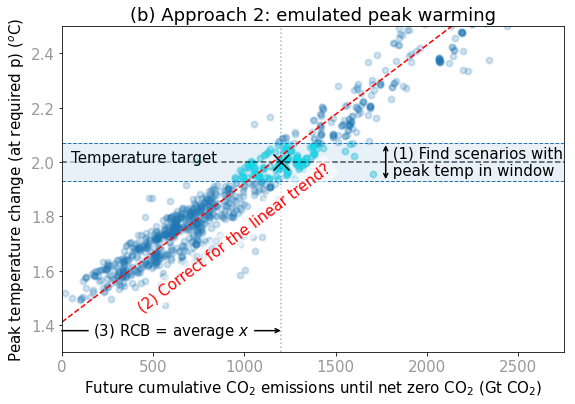

In [11]:
# Now plot approach 2
window = 0.07
fig, ax1 = plt.subplots(figsize=(9, 6))
x = 'Cumulative net CO2 (2020 to netzero, Gt CO2) (Harm-Infilled)'
y = 'Median peak warming (MAGICCv7.5.3)'

ax1.set_ylabel(
    'Peak temperature change (at required p) ($^o$C)', fontsize=fontsize, color='black'
)
ax1.set_xlabel('Future cumulative CO$_2$ emissions until net zero CO$_2$ (Gt CO$_2$)', fontsize=fontsize, color='black')

ax1.scatter(
    ar6meta[x] - offset2024,
    ar6meta[y],
    label='Total CO2 Emissions',
    linewidth=2, 
    alpha=0.2,
)

# Highlight selected scenarios
selected_scenarios = ar6meta[
    ar6meta[y].between(TARGET_Y_1-window, TARGET_Y_1+window)
]
selected_spread = selected_scenarios[x].std()
print(f"Spread of scenarios in window is {selected_spread}")

ax1.scatter(
    selected_scenarios[x] - offset2024, 
    selected_scenarios[y],
    color="cyan", 
    label='Total CO2 Emissions',
    linewidth=2, 
    alpha=0.2,
)

# Add mean point
meanpoint = selected_scenarios[x].mean() - offset2024

ax1.grid(False)

# Horizontal lines and labels
ax1.set_xlim([0, 2750])
ax1.set_ylim([1.3, 2.5])

ax1.axhline(y=TARGET_Y_1, color='black', linestyle='--', linewidth=1.5, alpha=0.7, zorder=1)

ax1.text(
    ax1.get_xlim()[0] + 50, 
    TARGET_Y_1, 
    "Temperature target", 
    color="black", 
    fontsize=fontsize, 
    ha='left',
    bbox=dict(boxstyle="round,pad=0.3", fc=BG_COLOR, alpha=0.6, ec="none"),
    zorder=1
)

y_upper = TARGET_Y_1 + window
y_lower = TARGET_Y_1 - window

# Draw the two lines
ax1.axhline(y_upper, linestyle='--', linewidth=1)
ax1.axhline(y_lower, linestyle='--', linewidth=1)

# Arrow showing the window
ax1.annotate(
    '',
    xy=(0.645, y_lower),
    xytext=(0.645, y_upper),
    xycoords=('axes fraction', 'data'),
    arrowprops=dict(
        arrowstyle='<->',
        linewidth=1.5
    )
)

# Label for the arrow
ax1.text(
    0.65,
    TARGET_Y_1,
    ' (1) Find scenarios with \n peak temp in window',
    transform=ax1.get_yaxis_transform(),
    va='center',
    ha='left',
    fontsize=fontsize
)

# Transparent band between the lines
ax1.axhspan(
    y_lower,
    y_upper,
    alpha=0.1
)

# Add correction line
correction_line_a, correction_line_b = np.polyfit(
    ar6meta[x] - offset2024,
    ar6meta[y],
    1
)
x = np.array([0, 2500])
ax1.plot(x, correction_line_a * x + correction_line_b, linestyle="--", c="red")
ax1.text(
    400,
    1.45,
    "(2) Correct for the linear trend?",
    rotation=37,
    fontsize=fontsize,
    c="red",
    bbox=dict(boxstyle="round,pad=0.3", fc=BG_COLOR, alpha=0.6, ec="none") 
)

ax1.scatter(
    [meanpoint], [TARGET_Y_1], marker="x", s=250, color="black"
)
print(f"Mean point is: {meanpoint}")

ARROW_Y_LEVEL_1 = 1.38
ax1.annotate(
    '',
    xy=(0, ARROW_Y_LEVEL_1),
    xytext=(meanpoint, ARROW_Y_LEVEL_1),
    arrowprops=dict(
        arrowstyle="<-", 
        color='black', 
        linewidth=1.5,
        shrinkA=0, shrinkB=0, 
        connectionstyle="arc3,rad=0"
    ),
)
ax1.text(
    600,
    ARROW_Y_LEVEL_1, 
    "(3) RCB = average $x$",
    fontsize=fontsize,
    ha='center',
    va='center',
    bbox=dict(boxstyle="round,pad=0.3", fc=BG_COLOR, alpha=1.0, ec="none") 
)
ax1.axvline(meanpoint, linestyle=":", alpha=0.5)

for label in ax1.get_xticklabels() + ax1.get_yticklabels():
    label.set_alpha(0.4)
    label.set_fontsize(fontsize)

plt.title('(b) Approach 2: emulated peak warming', fontsize=titlefont)
plt.savefig("./output/Approach2.png", dpi=300, bbox_inches='tight')

In [12]:
ar6meta.columns

Index(['Model', 'Scenario', 'Category', 'Category_name', 'Category_subset',
       'Subset_Ch4', 'Category_Vetting_historical', 'IMP_marker',
       'Literature Reference (if applicable)', 'Policy_category',
       'Policy_category_name', 'Project_study', 'CO2 emissions 2030 Gt CO2/yr',
       'CO2 emissions 2050 Gt CO2/yr', 'CO2 emissions 2100 Gt CO2/yr', 'COVID',
       'GDP|MER-per-capita-in-2100', 'GDP|MER-per-capita-in-2100_bin',
       'GHG emissions 2030 Gt CO2-equiv/yr (Harmonized-Infilled)',
       'GHG emissions 2050 Gt CO2-equiv/yr (Harmonized-Infilled)',
       'GHG emissions 2100 Gt CO2-equiv/yr (Harmonized-Infilled)',
       'GHG emissions reductions 2019-2030 % modelled Harmonized-Infilled',
       'GHG emissions reductions 2019-2040 % modelled Harmonized-Infilled',
       'GHG emissions reductions 2019-2050 % modelled Harmonized-Infilled',
       'CO2 emissions reductions 2019-2030 % modelled Harmonized-Infilled',
       'CO2 emissions reductions 2019-2040 % modelled Ha

Temp 1.5, uncorrected budget: 444.49276001742595, corrected budget: 397.49340884515544
Temp 2.0, uncorrected budget: 1419.7891848999996, corrected budget: 1421.4063974491958


C:\Users\rlamboll\AppData\Local\Temp\ipykernel_2712\949154672.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  validScens[z] = validScens[x] - (validScens[y] - temp) / TCRE
C:\Users\rlamboll\AppData\Local\Temp\ipykernel_2712\949154672.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  validScens[z] = validScens[x] - (validScens[y] - temp) / TCRE


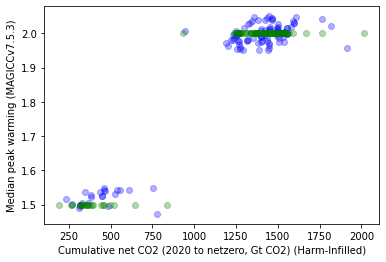

In [63]:
# Calculate the budget according to the AR6 methodology
x = 'Cumulative net CO2 (2020 to netzero, Gt CO2) (Harm-Infilled)'
y = 'Median peak warming (MAGICCv7.5.3)'
z = 'Corrected cumulative net CO2'
# We want to apply a TCRE-based correction between intended temperature peak and the actual peak
TCRE = 0.45/1000
window = 0.05
ar6meta = ar6meta[pd.to_numeric(ar6meta[y], errors='coerce').notna()]
for temp in [1.5, 2.0]:
    validScens = ar6meta[abs(ar6meta[y] - temp) < window]
    validScens[z] = validScens[x] - (validScens[y] - temp) / TCRE
    plt.scatter(validScens[x], validScens[y], alpha=0.3, c="blue")
    plt.scatter(validScens[z], [temp]*validScens.shape[0], alpha=0.3, c="green")
    plt.xlabel(x)
    plt.ylabel(y)
    #plt.legend(["uncorrected budgets", "corrected budgets", "hidden values"])
    print(f'Temp {temp}, uncorrected budget: {validScens[x].mean()}, corrected budget: {validScens[z].mean()}')

In [14]:
ar6meta.columns

Index(['Model', 'Scenario', 'Category', 'Category_name', 'Category_subset',
       'Subset_Ch4', 'Category_Vetting_historical', 'IMP_marker',
       'Literature Reference (if applicable)', 'Policy_category',
       'Policy_category_name', 'Project_study', 'CO2 emissions 2030 Gt CO2/yr',
       'CO2 emissions 2050 Gt CO2/yr', 'CO2 emissions 2100 Gt CO2/yr', 'COVID',
       'GDP|MER-per-capita-in-2100', 'GDP|MER-per-capita-in-2100_bin',
       'GHG emissions 2030 Gt CO2-equiv/yr (Harmonized-Infilled)',
       'GHG emissions 2050 Gt CO2-equiv/yr (Harmonized-Infilled)',
       'GHG emissions 2100 Gt CO2-equiv/yr (Harmonized-Infilled)',
       'GHG emissions reductions 2019-2030 % modelled Harmonized-Infilled',
       'GHG emissions reductions 2019-2040 % modelled Harmonized-Infilled',
       'GHG emissions reductions 2019-2050 % modelled Harmonized-Infilled',
       'CO2 emissions reductions 2019-2030 % modelled Harmonized-Infilled',
       'CO2 emissions reductions 2019-2040 % modelled Ha

Text(0, 0.5, 'Median warming at year of netzero Emissions|CO2 (MAGICCv7.5.3)')

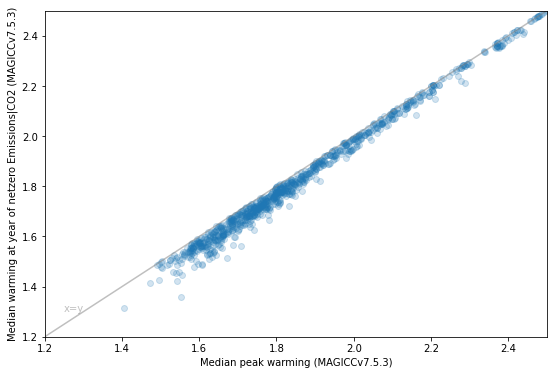

In [15]:
fig, ax1 = plt.subplots(figsize=(9, 6))
x = 'Median peak warming (MAGICCv7.5.3)'
y = 'Median warming at year of netzero Emissions|CO2 (MAGICCv7.5.3)'
ax1.scatter(ar6meta[x], ar6meta[y], alpha=0.2)
ax1.plot([0, 3], [0, 3], alpha = 0.5, c="grey")
ax1.text(1.25, 1.3, "x=y", c="grey", alpha=0.5)
ax1.set_xlim([1.2, 2.5])
ax1.set_ylim([1.2, 2.5])
ax1.set_xlabel(x)
ax1.set_ylabel(y)

Running Median warming in 2100 (FaIRv1.6.2)
Spread of scenarios in window is 137.98864832805648
Mean point is: 649.7069914097749
Running Median warming in 2100 (MAGICCv7.5.3)
Spread of scenarios in window is 149.67724999888074
Mean point is: 576.7073232958527


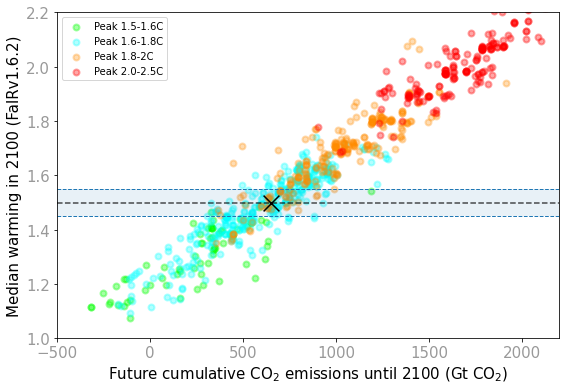

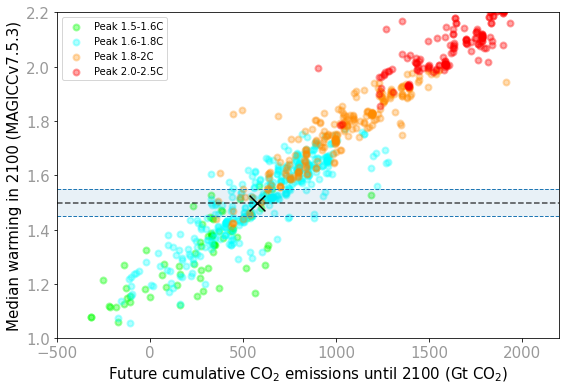

In [16]:
# Calculate relationship for end century warming
window = 0.05
TARGET_Y_1 = 1.5
for y in [
    'Median warming in 2100 (FaIRv1.6.2)', 'Median warming in 2100 (MAGICCv7.5.3)', 
    
]:
    print(f"Running {y}")
    fig, ax1 = plt.subplots(figsize=(9, 6))
    x = "Cumulative net CO2 (2020-2100, Gt CO2) (Harm-Infilled)"
    ax1.set_ylabel(
        y, fontsize=fontsize, color='black'
    )
    ax1.set_xlabel('Future cumulative CO$_2$ emissions until 2100 (Gt CO$_2$)', fontsize=fontsize, color='black')

    # Highlight selected scenarios
    selected_scenarios = ar6meta[
        ar6meta['Median peak warming (MAGICCv7.5.3)'].between(1.5, 1.6)
    ]

    ax1.scatter(
        selected_scenarios[x], 
        selected_scenarios[y],
        color="lime", 
        label='Total CO2 Emissions',
        linewidth=2, 
        alpha=0.35,
    )

    # Highlight some scenarios
    selected_scenarios = ar6meta[
        ar6meta['Median peak warming (MAGICCv7.5.3)'].between(1.6, 1.8)
    ]

    ax1.scatter(
        selected_scenarios[x], 
        selected_scenarios[y],
        color="cyan", 
        label='Total CO2 Emissions',
        linewidth=2, 
        alpha=0.3,
    )
    selected_scenarios = ar6meta[
        ar6meta['Median peak warming (MAGICCv7.5.3)'].between(1.8, 2.0)
    ]

    ax1.scatter(
        selected_scenarios[x], 
        selected_scenarios[y],
        color="darkorange", 
        label='Total CO2 Emissions',
        linewidth=2, 
        alpha=0.3,
    )


    selected_scenarios = ar6meta[
        ar6meta['Median peak warming (MAGICCv7.5.3)'].between(2.0, 2.5)
    ]
    ax1.scatter(
        selected_scenarios[x], 
        selected_scenarios[y],
        color="red", 
        label='Total CO2 Emissions',
        linewidth=2, 
        alpha=0.35,
    )
    # Add mean point for selected scenarios
    selected_scenarios = ar6meta[ar6meta[y].between(1.5-window, 1.5+window)]
    meanpoint = selected_scenarios[x].mean()
    selected_spread = selected_scenarios[x].std()
    print(f"Spread of scenarios in window is {selected_spread}")
    print(f"Mean point is: {meanpoint}")

    ax1.grid(False)

    # Horizontal lines and labels
    ax1.set_xlim([-500, 2200])
    ax1.set_ylim([1.0, 2.2])

    ax1.axhline(y=TARGET_Y_1, color='black', linestyle='--', linewidth=1.5, alpha=0.7)

    y_upper = TARGET_Y_1 + window
    y_lower = TARGET_Y_1 - window

    # Draw the two lines
    ax1.axhline(y_upper, linestyle='--', linewidth=1)
    ax1.axhline(y_lower, linestyle='--', linewidth=1)

    # Transparent band between the lines
    ax1.axhspan(
        y_lower,
        y_upper,
        alpha=0.1
    )


    ax1.scatter(
        [meanpoint], [TARGET_Y_1], marker="x", s=250, color="black"
    )

    plt.legend(["Peak 1.5-1.6C", "Peak 1.6-1.8C", "Peak 1.8-2C", "Peak 2.0-2.5C"])
    for label in ax1.get_xticklabels() + ax1.get_yticklabels():
        label.set_alpha(0.4)
        label.set_fontsize(fontsize)

# Approach 3
this requires some more data from the AR6 database

In [17]:
ar6 = pyam.IamDataFrame("./input/AR6_Scenarios_Database_World_v1.1.csv")

pyam - INFO: Running in a notebook, setting up a basic logging at level INFO
pyam.core - INFO: Reading file input\AR6_Scenarios_Database_World_v1.1.csv


In [18]:
ar6harm = pyam.IamDataFrame("./input/1652361598937-ar6_emissions_vetted_infillerdatabase_10.5281-zenodo.6390768 (1).csv")

pyam.core - INFO: Reading file input\1652361598937-ar6_emissions_vetted_infillerdatabase_10.5281-zenodo.6390768 (1).csv


In [19]:
infillstring = "AR6 climate diagnostics|Harmonized|"
co2 = "Emissions|CO2"
eni = "|Energy and Industrial Processes"
afolu = "|AFOLU"

useful = ar6harm.filter(variable=infillstring + co2 + "*").add(
    infillstring+co2+eni, infillstring+co2+afolu, co2, ignore_units=True
)
tempfair = 'AR6 climate diagnostics|Surface Temperature (GSAT)|FaIRv1.6.2|50.0th Percentile'
tempmagicc = 'AR6 climate diagnostics|Surface Temperature (GSAT)|MAGICCv7.5.3|50.0th Percentile'
useful = pyam.concat([useful, ar6.filter(variable=[tempfair, tempmagicc])])
useful = useful.interpolate(time=range(2015, 2101)).filter(year=range(2015, 2101))
assert useful.timeseries().isna().sum().sum() == 0
useful_ts = useful.timeseries().reset_index().drop(columns=["unit"])

In [20]:
def make_long(df):
    # This flips a dataframe to have different variable names as the columns and 
    # model/scenario/years as rows
    return df.melt(
        id_vars=["model", "scenario", "region", "variable"], 
        var_name="year", 
        value_name="value"
    ).pivot_table(
        index=["model", "scenario", "region", "year"], 
        columns="variable", 
        values="value"
    )

In [21]:
# Calculate the offset for scenarios starting in 2015
cum_co2_2014 = combined_df["Cumulative CO2"][combined_df.Year==2014].iloc[0]
cum_co2_2014

2348.5005771781985

In [22]:
useful_long = make_long(useful_ts).dropna()
cumco2 = "Cumulative CO2"
useful_long[cumco2] = useful_long.groupby(["model", "scenario", "region"])[co2].cumsum()

In [23]:
useful_long["CumCO2Gt"] = useful_long["Cumulative CO2"] /1000 + cum_co2_2014

In [24]:
useful_long_abbr = useful_long.iloc[:len(useful_long)//8]
useful_long_abbr

variable                               AR6 climate diagnostics|Surface Temperature (GSAT)|FaIRv1.6.2|50.0th Percentile  \
model       scenario      region year                                                                                    
AIM/CGE 2.0 SSP1-26       World  2015                                           1.111952                                 
                                 2016                                           1.139538                                 
                                 2017                                           1.167658                                 
                                 2018                                           1.192135                                 
                                 2019                                           1.214610                                 
...                                                                                  ...                                 
GCAM 4.2    SSP3-Baseline World  2031                                           1.472335                                 
                                 2032                                           1.496835                                 
                                 2033                                           1.523896                                 
                                 2034                                           1.557545                                 
                                 2035                                           1.592545                                 

variable                               AR6 climate diagnostics|Surface Temperature (GSAT)|MAGICCv7.5.3|50.0th Percentile  \
model       scenario      region year                                                                                      
AIM/CGE 2.0 SSP1-26       World  2015                                           1.115698                                   
                                 2016                                           1.135078                                   
                                 2017                                           1.155381                                   
                                 2018                                           1.176737                                   
                                 2019                                           1.200106                                   
...                                                                                  ...                                   
GCAM 4.2    SSP3-Baseline World  2031                                           1.519773                                   
                                 2032                                           1.554291                                   
                                 2033                                           1.591403                                   
                                 2034                                           1.631249                                   
                                 2035                                           1.672344                                   

variable                               Emissions|CO2  Cumulative CO2  \
model       scenario      region year                                  
AIM/CGE 2.0 SSP1-26       World  2015   39152.726300    3.915273e+04   
                                 2016   38814.585500    7.796731e+04   
                                 2017   38476.509144    1.164438e+05   
                                 2018   38138.497233    1.545823e+05   
                                 2019   37800.549767    1.923829e+05   
...                                              ...             ...   
GCAM 4.2    SSP3-Baseline World  2031   54680.522980    8.069891e+05   
                                 2032   55335.175268    8.623243e+05   
                                 2033   55989.704210    9.183140e+05   
        

In [25]:
# 1. Filter the dataframe for rows where tempmagicc is greater than 2
above_threshold = useful_long[useful_long[tempmagicc] > TARGET_Y_1]

In [26]:
# 2. Group by the levels you want to preserve (model, scenario, region)
# and find the index label (idxmin) where tempmagicc is the lowest (closest to 2)
idx_of_smallest_exceedance = above_threshold.groupby(
    level=['model', 'scenario', 'region']
)[tempmagicc].idxmin()

# 3. Use .loc with those indices to pull out the CumCO2Gt values
temp_exceed_budget = useful_long.loc[idx_of_smallest_exceedance, 'CumCO2Gt']
mean_temp_exceed_budget = temp_exceed_budget.mean()
mean_temp_exceed_budget

3035.2096225144633

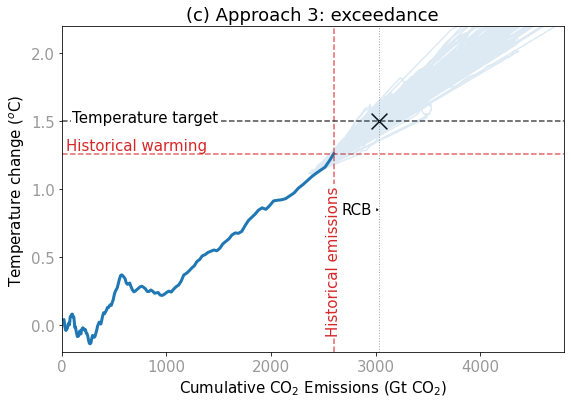

In [27]:
# --- Calculate uncertainty ---

temp_error = 0.12 # The uncertainty in observed temperature, from AR6 WG1

# Define the vertices for the shaded triangle. Uncertainty in cum CO2 is 10% (from AR6 WG1)
cone_vertices = np.array([
    [0.0, 0.0],
    [last_co2*0.9, last_temp+temp_error],
    [last_co2*1.1, last_temp-temp_error],
])

slope, intercept = np.polyfit(
    combined_df['Cumulative CO2'][~combined_df.meanTemp.isna()], 
    combined_df['meanTemp'][~combined_df.meanTemp.isna()],
    1
)

# --- Plotting Code ---

fig, ax1 = plt.subplots(figsize=(9, 6))

ax1.set_ylabel('Temperature change ($^o$C)', fontsize=fontsize, color='black') 
ax1.set_xlabel('Cumulative CO$_2$ Emissions (Gt CO$_2$)', fontsize=fontsize, color='black')

# --- A. Plotting Data and Cone ---

ax1.plot(
    combined_df['Cumulative CO2'], 
    combined_df['meanTemp'], 
    color=color_co2, 
    label='Total CO2 Emissions',
    linewidth=3
)

ax1.grid(False)
ax1.set_ylim([-0.2, 2.2])
ax1.set_xlim([0, 4800])

# --- B. Horizontal RCB Arrows ---

# Define Y-positions for the arrows below the plot
ARROW_Y_LEVEL_1 = 0.85 

# Arrow 1: RCB
ax1.annotate(
    '',
    xy=(mean_temp_exceed_budget, ARROW_Y_LEVEL_1),
    xytext=(last_co2, ARROW_Y_LEVEL_1),
    arrowprops=dict(
        arrowstyle="->", 
        color='black', 
        linewidth=1.5,
        shrinkA=0, shrinkB=0, 
        connectionstyle="arc3,rad=0"
    ),
)
ax1.text(
    (last_co2 + mean_temp_exceed_budget) / 2, 
    ARROW_Y_LEVEL_1, 
    "RCB",
    fontsize=fontsize,
    ha='center',
    va='center',
    bbox=dict(boxstyle="round,pad=0.3", fc=BG_COLOR, alpha=1.0, ec="none") 
)


# --- C. Vertical Dashed Lines and Text ---

# 1. Vertical line at Historical Emissions
ax1.axvline(
    x=last_co2, 
    color=HISTORICAL_COLOR, 
    linestyle='--', 
    linewidth=1.5, 
    alpha=0.7
)
# Label "Historical emissions"
ax1.text(
    last_co2, 
    -0.08, 
    "Historical emissions", 
    color=HISTORICAL_COLOR, 
    fontsize=fontsize,
    ha='center',
    va='bottom',
    rotation=90,
    bbox=dict(boxstyle="square,pad=0.1", fc=BG_COLOR, ec="none") 
)

# 2. Vertical line at best RCB
ax1.axvline(x=mean_temp_exceed_budget, color='grey', linestyle=':', linewidth=1.0, alpha=0.7)


# --- D. Other Lines and Annotations ---

# Historical warming line
ax1.axhline(
    y=last_temp, 
    color=HISTORICAL_COLOR, 
    linestyle='--', 
    linewidth=1.5, 
    alpha=0.7
)
ax1.text(
    ax1.get_xlim()[0] + 40, 
    last_temp + 0.03, 
    "Historical warming", 
    color=HISTORICAL_COLOR, 
    fontsize=fontsize, 
    ha='left'
)

# Horizontal lines and labels
ax1.axhline(y=TARGET_Y_1, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
ax1.text(
    ax1.get_xlim()[0] + 100, 
    TARGET_Y_1 + 0.03, 
    "Temperature target", 
    color="black", 
    fontsize=fontsize, 
    ha='left',
    va="center",
    bbox=dict(boxstyle="square,pad=0.1", fc=BG_COLOR, ec="none") 
)

# --- D. Draw scenarios on ---

ax1.plot(useful_long_abbr["CumCO2Gt"], useful_long_abbr[tempmagicc], alpha=0.15)
ax1.scatter([mean_temp_exceed_budget], [TARGET_Y_1], marker="x", s=250, color="black")


# --- E. Final Customization ---
plt.title('(c) Approach 3: exceedance', fontsize=titlefont) 
for label in ax1.get_xticklabels() + ax1.get_yticklabels():
    label.set_alpha(0.4)
    label.set_fontsize(fontsize)
plt.savefig("./output/Approach3.png", dpi=300, bbox_inches='tight')

In [28]:
ar6meta[(ar6meta['Median warming in 2100 (MAGICCv7.5.3)']<1.5)]['Exceedance Probability 2.0C (MAGICCv7.5.3)'].max()

0.3266666666666666

# Plot figure for approach 4

In [29]:
scen = ar6.filter(scenario="SSP1-26", model="MESSAGE*")
years=np.arange(2005, 2051)
fairtemp = 'AR6 climate diagnostics|Surface Temperature (GSAT)|FaIRv1.6.2|50.0th Percentile'
temps = scen.filter(variable=fairtemp, year=years).timeseries()
temps = temps + 0.15 * np.random.normal(0, 0.1, size=temps.shape)
ems = scen.filter(variable=co2, year=years).interpolate(years).timeseries() / 1000
ems

,,,,,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,...,2041,2042,2043,2044,2045,2046,2047,2048,2049,2050
model,scenario,region,variable,unit,,,,,,,,,,,,,,,,,,,,,
MESSAGE-GLOBIOM 1.0,SSP1-26,World,Emissions|CO2,Mt CO2/yr,37.720381,38.229845,38.739308,39.248772,39.758235,40.267699,40.082973,39.898247,39.713521,39.528795,...,27.300557,26.466522,25.632486,24.798451,23.964415,23.13038,22.296345,21.462309,20.628274,19.794238


In [30]:
def add_connecting_arrow(year, df_top, df_bottom, direction='down', rad=0.2, alpha=1):
    idx = df_top.columns.get_loc(year)
    y_top = df_top.iloc[0, idx]
    y_bottom = df_bottom.iloc[0, idx]
    
    if direction == 'down':
        ax_start, ax_end = ax1, ax2
        xy_start, xy_end = (year, y_top), (year, y_bottom)
    else:
        ax_start, ax_end = ax2, ax1
        xy_start, xy_end = (year, y_bottom), (year, y_top)
    
    arrow = ConnectionPatch(
        xyA=xy_start, xyB=xy_end, 
        coordsA="data", coordsB="data",
        axesA=ax_start, axesB=ax_end,
        arrowstyle="-|>", 
        connectionstyle=f"arc3,rad={rad}", 
        color="black", lw=1.5, mutation_scale=15,
        alpha=alpha
    )
    fig.add_artist(arrow)

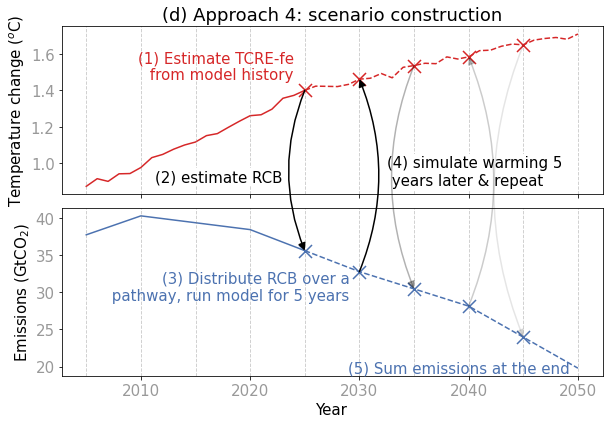

In [31]:
# Initialize the figure and axes
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8.7, 6), sharex=True)
ax1.set_title('(d) Approach 4: scenario construction', fontsize=titlefont) 

# 1. Plot Temperature (Top)
hist_yrs = [y for y in temps.columns if y <= 2025]
proj_yrs = [y for y in temps.columns if y >= 2025]
ax1.plot(hist_yrs, temps[hist_yrs].iloc[0], color=HISTORICAL_COLOR, label='Historical')
ax1.plot(proj_yrs, temps[proj_yrs].iloc[0], color=HISTORICAL_COLOR, linestyle='--', label='Projected')

# 2. Plot Emissions (Bottom)
ax2.plot(hist_yrs, ems[hist_yrs].iloc[0], color=ARROW_BLUE, label='Historical')
ax2.plot(proj_yrs, ems[proj_yrs].iloc[0], color=ARROW_BLUE, linestyle='--', label='Projected')

# 3. Scatter points (2025 to 2050)
scatter_years = [yr for yr in range(2025, max(years), 5) if yr in temps.columns]
ax1.scatter(scatter_years, temps[scatter_years].iloc[0], color=HISTORICAL_COLOR, zorder=5, marker="x", s=170)
ax2.scatter(scatter_years, ems[scatter_years].iloc[0], color=ARROW_BLUE, zorder=5, marker="x", s=170)

# 4. Vertical dashed lines
for yr in range(int(min(temps.columns)), int(max(temps.columns)) + 1, 5):
    ax1.axvline(x=yr, color='gray', linestyle='--', linewidth=0.9, alpha=0.4)
    ax2.axvline(x=yr, color='gray', linestyle='--', linewidth=0.9, alpha=0.4)

# 5. Connecting Arrows
add_connecting_arrow(2025, temps, ems, direction='down')
add_connecting_arrow(2030, temps, ems, direction='up')
add_connecting_arrow(2035, temps, ems, direction='down', alpha=0.3)
add_connecting_arrow(2040, temps, ems, direction='up', alpha=0.2)
add_connecting_arrow(2045, temps, ems, direction='down', alpha=0.1)

# 6. Labels, Annotations, and Font Sizing
ax1.set_ylabel('Temperature change ($^o$C)', fontsize=fontsize)
ax2.set_ylabel('Emissions (GtCO$_2$)', fontsize=fontsize)
ax2.set_xlabel('Year', fontsize=fontsize)

# Apply font size to ticks
ax1.tick_params(axis='both', labelsize=fontsize)
ax2.tick_params(axis='both', labelsize=fontsize)

# Annotations at 2025 with rotation
ax1.annotate("(1) Estimate TCRE-fe\n from model history", xy=(2024, temps[2025].iloc[0]*1.03), 
             xytext=(0, 0), textcoords='offset points', 
             color=HISTORICAL_COLOR, 
             fontsize=fontsize, horizontalalignment='right', verticalalignment="bottom")
ax1.annotate("(2) estimate RCB", xy=(2023, 0.9), 
            fontsize=fontsize, horizontalalignment="right", 
            bbox=dict(boxstyle="square,pad=0.1", fc=BG_COLOR, ec="none"),
             zorder=11
)
ax2.annotate("(3) Distribute RCB over a\n pathway, run model for 5 years", xy=(2030, ems[2030]), 
             xytext=(-10, -15), textcoords='offset points', 
             color=ARROW_BLUE, horizontalalignment="right", verticalalignment="center", 
             fontsize=fontsize)
ax1.annotate("(4) simulate warming 5\n years later & repeat", xy=(2032.5, 0.88),
            fontsize=fontsize, horizontalalignment="left", 
            bbox=dict(boxstyle="square,pad=0.1", fc=BG_COLOR, ec="none"),
            zorder=11
)
ax2.annotate("(5) Sum emissions at the end", xy=(2050, ems[2050]), 
             xytext=(-8, 0), textcoords='offset points', 
             color=ARROW_BLUE, horizontalalignment="right", verticalalignment="center", 
             fontsize=fontsize)


# --- Final Customization ---

for label in ax1.get_xticklabels() + ax1.get_yticklabels() + ax2.get_xticklabels() + ax2.get_yticklabels() :
    label.set_alpha(0.4)
    label.set_fontsize(fontsize)
plt.tight_layout()
plt.savefig("./output/Approach4.png", dpi=300, bbox_inches='tight')

# Sandbox

In [32]:
toPlot = pd.merge(
    ar6meta.rename(columns={"Model": "model", "Scenario": "scenario"}), 
    ar6.filter(variable="Emissions|Sulfur", year=2100).timeseries().reset_index().rename(columns={2100: "SulfurEnd"}),
    on=['model', 'scenario'], how='inner'
)
toPlot = pd.merge(
    toPlot, 
    ar6.filter(variable="Emissions|BC", year=2100).timeseries().reset_index().rename(columns={2100: "BCEnd"}),
    on=['model', 'scenario'], how='inner'
)
toPlot = pd.merge(
    toPlot, 
    ar6.filter(variable="Emissions|CH4", year=2100).timeseries().reset_index().rename(columns={2100: "CH4End"}),
    on=['model', 'scenario'], how='inner'
)
toPlot = pd.merge(
    toPlot, 
    ar6.filter(variable="Emissions|OC", year=2100).timeseries().reset_index().rename(columns={2100: "OCEnd"}),
    on=['model', 'scenario'], how='inner'
)
toPlot

C:\Users\rlamboll\AppData\Local\Temp\ipykernel_2712\2313338779.py:16: FutureWarning: Passing 'suffixes' which cause duplicate columns {'region_x', 'unit_x', 'variable_x'} in the result is deprecated and will raise a MergeError in a future version.
  toPlot = pd.merge(


,model,scenario,Category,Category_name,Category_subset,Subset_Ch4,Category_Vetting_historical,IMP_marker,Literature Reference (if applicable),Policy_category,...,unit_y,BCEnd,region_x,variable_x,unit_x,CH4End,region_y,variable_y,unit_y,OCEnd
0,AIM/CGE 2.0,SSP1-26,C3,C3: limit warming to 2°C (>67%),C3y_+veGHGs,Limit to 2C (>67%) immediate 2020 action,C3,non-IMP,https://doi.org/10.1016/j.gloenvcha.2016.05.009,P2a,...,Mt BC/yr,1.915300,World,Emissions|CH4,Mt CH4/yr,113.140500,World,Emissions|OC,Mt OC/yr,13.796800
1,AIM/CGE 2.0,SSP1-34,C5,C5: limit warming to 2.5°C (>50%),C5,NaN,C5,non-IMP,https://doi.org/10.1016/j.gloenvcha.2016.05.009,P2a,...,Mt BC/yr,1.813500,World,Emissions|CH4,Mt CH4/yr,145.372100,World,Emissions|OC,Mt OC/yr,12.949700
2,AIM/CGE 2.0,SSP1-45,C6,C6: limit warming to 3°C (>50%),C6,NaN,C6,non-IMP,https://doi.org/10.1016/j.gloenvcha.2016.05.009,P2a,...,Mt BC/yr,1.787000,World,Emissions|CH4,Mt CH4/yr,177.757200,World,Emissions|OC,Mt OC/yr,12.739700
3,AIM/CGE 2.0,SSP1-Baseline,C7,C7: limit warming to 4°C (>50%),C7,NaN,C7,non-IMP,https://doi.org/10.1016/j.gloenvcha.2016.05.009,P1a,...,Mt BC/yr,1.818500,World,Emissions|CH4,Mt CH4/yr,465.455900,World,Emissions|OC,Mt OC/yr,13.170000
4,AIM/CGE 2.0,SSP4-26,C3,C3: limit warming to 2°C (>67%),C3y_+veGHGs,Limit to 2C (>67%) immediate 2020 action,C3,non-IMP,https://doi.org/10.1016/j.gloenvcha.2016.05.009,P2a,...,Mt BC/yr,3.795800,World,Emissions|CH4,Mt CH4/yr,148.164300,World,Emissions|OC,Mt OC/yr,23.757600
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
954,WITCH-GLOBIOM 4.2,EMF30_D_Frozen-CH4,C8,C8: exceed warming of 4°C (>=50%),C8,NaN,C8,non-IMP,https://doi.org/10.1007/s10584-020-02938-5,P0,...,Mt BC/yr,1.004205,World,Emissions|CH4,Mt CH4/yr,610.390048,World,Emissions|OC,Mt OC/yr,3.155827
955,WITCH-GLOBIOM 4.2,EMF30_D_Frozen-EF,C7,C7: limit warming to 4°C (>50%),C7,NaN,C7,non-IMP,https://doi.org/10.1007/s10584-020-02938-5,P0,...,Mt BC/yr,8.007688,World,Emissions|CH4,Mt CH4/yr,610.390048,World,Emissions|OC,Mt OC/yr,11.341785
956,WITCH-GLOBIOM 4.2,EMF30_D_Frozen-EF-EndU,C8,C8: exceed warming of 4°C (>=50%),C8,NaN,C8,non-IMP,https://doi.org/10.1007/s10584-020-02938-5,P0,...,Mt BC/yr,3.987896,World,Emissions|CH4,Mt CH4/yr,411.713334,World,Emissions|OC,Mt OC/yr,6.828912
957,WITCH-GLOBIOM 4.2,EMF30_D_Frozen-EF-SLCF,C8,C8: exceed warming of 4°C (>=50%),C8,NaN,C8,non-IMP,https://doi.org/10.1007/s10584-020-02938-5,P0,...,Mt BC/yr,3.987896,World,Emissions|CH4,Mt CH4/yr,411.713334,World,Emissions|OC,Mt OC/yr,6.828912


In [33]:
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm

In [34]:
x = "Cumulative net CO2 (2020-2100, Gt CO2) (Harm-Infilled)"
cols = ['Cumulative net CO2 (2020-2100, Gt CO2) (Harm-Infilled)', "CH4End", "SulfurEnd", "BCEnd", "OCEnd"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(toPlot[cols])
y_scaled = StandardScaler().fit_transform(toPlot[[y]]).ravel()

X_scaled = sm.add_constant(X_scaled)

model = sm.OLS(y_scaled, X_scaled).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.993
Model:                            OLS   Adj. R-squared:                  0.993
Method:                 Least Squares   F-statistic:                 2.724e+04
Date:                Wed, 06 May 2026   Prob (F-statistic):               0.00
Time:                        17:39:54   Log-Likelihood:                 1022.0
No. Observations:                 959   AIC:                            -2032.
Df Residuals:                     953   BIC:                            -2003.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       9.281e-17      0.003   3.44e-14      1.0

KeyError: 'EndSulfur'

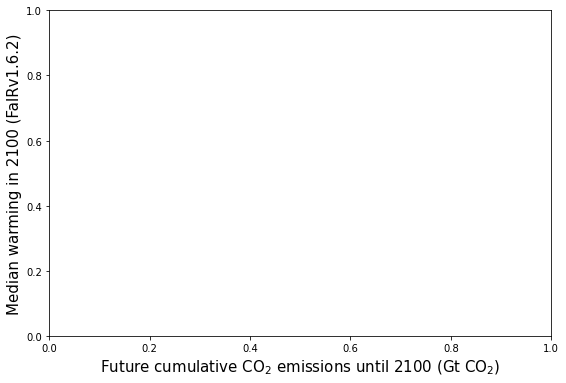

In [35]:
# Calculate relationship for end century warming
window = 0.05
TARGET_Y_1 = 1.5
for y in [
    'Median warming in 2100 (FaIRv1.6.2)', 'Median warming in 2100 (MAGICCv7.5.3)', 
    
]:
    fig, ax1 = plt.subplots(figsize=(9, 6))
    x = "Cumulative net CO2 (2020-2100, Gt CO2) (Harm-Infilled)"
    ax1.set_ylabel(
        y, fontsize=fontsize, color='black'
    )
    ax1.set_xlabel(
        'Future cumulative CO$_2$ emissions until 2100 (Gt CO$_2$)', 
        fontsize=fontsize, 
        color='black'
    )

    selected_scenarios = toPlot
    ax1.scatter(
        selected_scenarios[x], 
        selected_scenarios[y],
        color=selected_scenarios["EndSulfur"], 
        label='Total CO2 Emissions',
        linewidth=2, 
        alpha=0.35,
    )

    for label in ax1.get_xticklabels() + ax1.get_yticklabels():
        label.set_alpha(0.4)
        label.set_fontsize(fontsize)

In [ ]:
selected_scenarios.columns[-30:]